<a href="https://colab.research.google.com/github/Greeshma-S-Kunder/AML_LAB_assignments/blob/main/AML_LAB_ASSIGNMENT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
# LINEAR REGRESSION
# RIDGE REGRESSION
# LASSO REGRESSION
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import (LinearRegression,Ridge,Lasso)
from sklearn.metrics import (mean_squared_error,mean_absolute_error,r2_score)

df = pd.read_csv("placement.csv")

print("Dataset:")
print(df.head())

print("\nDataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

X = df.drop("package", axis=1)
y = df["package"]

print("\nInput features:")
print(X.head())

print("\nTarget:")
print(y.head())

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


#NORMAL LINEAR REGRESSION

linear_model = LinearRegression()
linear_model.fit(X_train_scaled,y_train)
linear_pred = linear_model.predict(X_test_scaled)


#EVALUATE LINEAR REGRESSION

linear_mse = mean_squared_error(y_test,linear_pred)
linear_rmse = np.sqrt(linear_mse)
linear_mae = mean_absolute_error(y_test,linear_pred)
linear_r2 = r2_score(y_test,linear_pred)

print("LINEAR REGRESSION")

print("Intercept:", linear_model.intercept_)
print("Coefficient:", linear_model.coef_)

print("MSE :", linear_mse)
print("RMSE:", linear_rmse)
print("MAE :", linear_mae)
print("R2  :", linear_r2)


#RIDGE REGRESSION

ridge_model = Ridge(
    alpha=1.0
)

ridge_model.fit(X_train_scaled,y_train)
ridge_pred = ridge_model.predict(X_test_scaled)


# EVALUATE RIDGE REGRESSION

ridge_mse = mean_squared_error(y_test,ridge_pred)
ridge_rmse = np.sqrt(ridge_mse)
ridge_mae = mean_absolute_error(y_test,ridge_pred)
ridge_r2 = r2_score(y_test,ridge_pred)

print("RIDGE REGRESSION (L2)")

print("Intercept:", ridge_model.intercept_)
print("Coefficient:", ridge_model.coef_)

print("MSE :", ridge_mse)
print("RMSE:", ridge_rmse)
print("MAE :", ridge_mae)
print("R2  :", ridge_r2)


#LASSO REGRESSION

lasso_model = Lasso(
    alpha=0.1
)

lasso_model.fit(X_train_scaled,y_train)
lasso_pred = lasso_model.predict(X_test_scaled)


#EVALUATE LASSO REGRESSION

lasso_mse = mean_squared_error(y_test,lasso_pred)
lasso_rmse = np.sqrt(lasso_mse)
lasso_mae = mean_absolute_error(y_test,lasso_pred)
lasso_r2 = r2_score(y_test,lasso_pred)

print("LASSO REGRESSION (L1)")

print("Intercept:", lasso_model.intercept_)
print("Coefficient:", lasso_model.coef_)

print("MSE :", lasso_mse)
print("RMSE:", lasso_rmse)
print("MAE :", lasso_mae)
print("R2  :", lasso_r2)


#COMPARE ALL THREE MODELS

comparison = pd.DataFrame({

    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression"
    ],

    "MSE": [
        linear_mse,
        ridge_mse,
        lasso_mse
    ],

    "RMSE": [
        linear_rmse,
        ridge_rmse,
        lasso_rmse
    ],

    "MAE": [
        linear_mae,
        ridge_mae,
        lasso_mae
    ],

    "R2 Score": [
        linear_r2,
        ridge_r2,
        lasso_r2
    ]
})
print("MODEL COMPARISON")
print(comparison.to_string(index=False))

# 12. PREDICT PACKAGE FOR CGPA = 9.5

test_data = pd.DataFrame(
    [[9.5]],
    columns=["cgpa"]
)

test_data_scaled = scaler.transform(
    test_data
)


linear_package = linear_model.predict(
    test_data_scaled
)

ridge_package = ridge_model.predict(
    test_data_scaled
)

lasso_package = lasso_model.predict(
    test_data_scaled
)


print("PREDICTION FOR CGPA = 9.5")

print(
    "Linear Regression:",
    linear_package[0]
)

print(
    "Ridge Regression:",
    ridge_package[0]
)

print(
    "Lasso Regression:",
    lasso_package[0]
)

Dataset:
   cgpa  package
0  6.89     3.26
1  5.12     1.98
2  7.82     3.25
3  7.42     3.67
4  6.94     3.57

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   cgpa     200 non-null    float64
 1   package  200 non-null    float64
dtypes: float64(2)
memory usage: 3.3 KB
None

Missing values:
cgpa       0
package    0
dtype: int64

Input features:
   cgpa
0  6.89
1  5.12
2  7.82
3  7.42
4  6.94

Target:
0    3.26
1    1.98
2    3.25
3    3.67
4    3.57
Name: package, dtype: float64
LINEAR REGRESSION
Intercept: 3.0127857142857146
Coefficient: [0.62931884]
MSE : 0.09995369482155113
RMSE: 0.31615454262362125
MAE : 0.2606898249919377
R2  : 0.7525945592908275
RIDGE REGRESSION (L2)
Intercept: 3.0127857142857146
Coefficient: [0.62485559]
MSE : 0.09995445790788206
RMSE: 0.31615574944618996
MAE : 0.2605697519339064
R2  : 0.7525926704991192


In [5]:
# DECISION TREE CLASSIFICATION
# Application of Gini Impurity, Entropy, Information Gain

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

df = pd.read_csv("data.csv")

print("Dataset before dropping unnecessary columns:\n")
print(df.head())

if 'id' in df.columns:
    df.drop(columns=['id'], inplace=True)

if 'Unnamed: 32' in df.columns:
    df.drop(columns=['Unnamed: 32'], inplace=True)

print("\nDataset after dropping unnecessary columns:\n")
print(df.head())

print("\nCategorical columns:")
print(df.select_dtypes(include='object').columns.tolist())

print("\nNumerical columns:")
print(df.select_dtypes(include=np.number).columns.tolist())


print("\nMissing values:")
missing = df.isnull().sum()

missing_percent = (missing / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": missing_percent
})

print(missing_table)

df['diagnosis'] = df['diagnosis'].map({
    'M': 1,
    'B': 0
})

X = df.drop('diagnosis', axis=1)
y = df['diagnosis']


print("\nClass distribution:")
print(y.value_counts())

print("\nClass distribution in percentage:")
print(y.value_counts(normalize=True))

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=42,stratify=y)

# DECISION TREE USING GINI IMPURITY

gini_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

gini_model.fit(X_train, y_train)

# Prediction
gini_pred = gini_model.predict(X_test)

# EVALUATE GINI MODEL

print("DECISION TREE USING GINI IMPURITY")

print("Accuracy:",accuracy_score(y_test, gini_pred))
print("Precision:",precision_score(y_test,gini_pred,average='weighted'))
print("Recall:",recall_score(y_test,gini_pred,average='weighted'))
print("F1 Score:",f1_score(y_test,gini_pred,average='weighted'))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, gini_pred))


# DECISION TREE USING ENTROPY

entropy_model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

entropy_model.fit(X_train, y_train)


# Prediction
entropy_pred = entropy_model.predict(X_test)


# EVALUATE ENTROPY MODEL

print("DECISION TREE USING ENTROPY / INFORMATION GAIN")
print("Accuracy:",accuracy_score(y_test, entropy_pred))
print("Precision:",precision_score(y_test,entropy_pred,average='weighted'))
print("Recall:",recall_score(y_test,entropy_pred,average='weighted'))
print("F1 Score:",f1_score(y_test,entropy_pred,average='weighted'))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, entropy_pred))


#COMPARE BOTH SPLITTING CRITERIA

comparison = pd.DataFrame({
    "Criterion": [
        "Gini Impurity",
        "Entropy / Information Gain"
    ],

    "Accuracy": [
        accuracy_score(y_test, gini_pred),
        accuracy_score(y_test, entropy_pred)
    ],

    "Precision": [
        precision_score(
            y_test,
            gini_pred,
            average='weighted'
        ),
        precision_score(
            y_test,
            entropy_pred,
            average='weighted'
        )
    ],

    "Recall": [
        recall_score(
            y_test,
            gini_pred,
            average='weighted'
        ),
        recall_score(
            y_test,
            entropy_pred,
            average='weighted'
        )
    ],

    "F1 Score": [
        f1_score(
            y_test,
            gini_pred,
            average='weighted'
        ),
        f1_score(
            y_test,
            entropy_pred,
            average='weighted'
        )
    ]
})

print("COMPARISON OF SPLITTING CRITERIA")

print(comparison.to_string(index=False))

Dataset before dropping unnecessary columns:

         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_

Dataset before removing unnecessary columns:
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_w

/tmp/ipykernel_2864/1984752644.py:78: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-z))


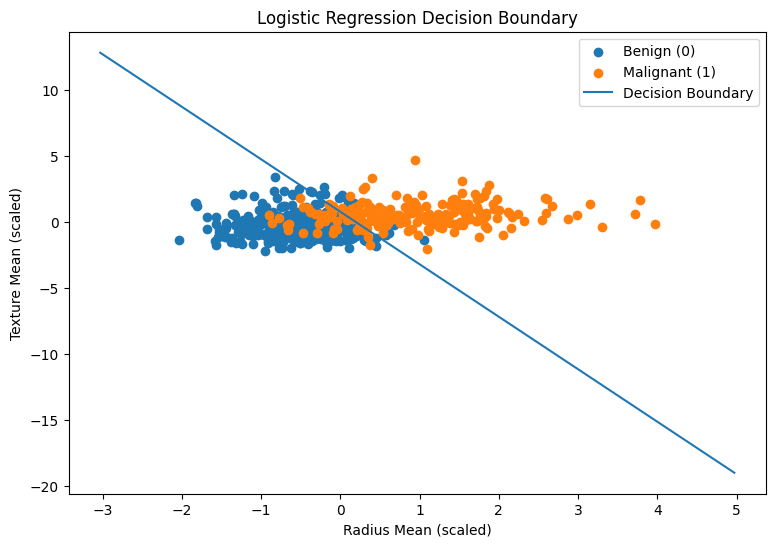

In [6]:
# LOGISTIC REGRESSION
# Sigmoid Function
# Decision Boundary
# L1 (Lasso) and L2 (Ridge) Regularization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# loading the dataset

df = pd.read_csv("data.csv")

print("Dataset before removing unnecessary columns:")
print(df.head())


# Remove unnecessary columns
if 'id' in df.columns:
    df.drop(columns=['id'], inplace=True)

if 'Unnamed: 32' in df.columns:
    df.drop(columns=['Unnamed: 32'], inplace=True)


print("\nDataset after removing id and Unnamed: 32:")
print(df.head())

print("\nCategorical columns:")
print(df.select_dtypes(include='object').columns.tolist())

print("\nNumerical columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

# M = Malignant = 1
# B = Benign    = 0

df['diagnosis'] = df['diagnosis'].map({
    'M': 1,
    'B': 0
})

X = df.drop('diagnosis', axis=1)
y = df['diagnosis']


print("\nNumber of features:", X.shape[1])
print("Number of samples:", X.shape[0])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)
#feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

#function to evaluate the model

def evaluate_model(model, model_name):
    model.fit(X_train_scaled, y_train)

    # Linear equation
    # z = β0 + β1x1 + β2x2 + ... + βnxn


    z = (
        model.intercept_[0]
        + np.dot(X_test_scaled, model.coef_[0])
    )

    # Apply sigmoid function

    probabilities = sigmoid(z)

    # Apply decision threshold
    # probability >= 0.5 → class 1 else it is 0


    pred_y = (probabilities >= 0.5).astype(int)

    #displaying intercept and final coefficients of the features

    print(model_name)

    print("\nIntercept:")
    print(model.intercept_)

    print("\nCoefficients:")

    for feature, coefficient in zip(
        X.columns,
        model.coef_[0]
    ):
        print(f"{feature}: {coefficient:.6f}")

    #Number of zero coefficients

    zero_coefficients = np.sum(
        model.coef_[0] == 0
    )

    print("\nNumber of zero coefficients:",
          zero_coefficients)

    print("\nFirst 10 sigmoid probabilities:")

    for i in range(10):
        print(
            f"Actual = {y_test.iloc[i]}, "
            f"Probability = {probabilities[i]:.4f}, "
            f"Prediction = {pred_y[i]}"
        )


    print("\nEvaluation:")

    print(
        "Accuracy :",
        accuracy_score(y_test, pred_y)
    )

    print(
        "Precision:",
        precision_score(
            y_test,
            pred_y,
            average='weighted'
        )
    )

    print(
        "Recall   :",
        recall_score(
            y_test,
            pred_y,
            average='weighted'
        )
    )

    print(
        "F1 Score :",
        f1_score(
            y_test,
            pred_y,
            average='weighted'
        )
    )

    cm = confusion_matrix(y_test, pred_y)

    print("\nConfusion Matrix:")
    print(cm)

    return model, probabilities, pred_y

# NORMAL LOGISTIC REGRESSION

logistic_model = LogisticRegression(
    penalty=None,
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

logistic_model, logistic_probabilities, logistic_predictions = (
    evaluate_model(
        logistic_model,
        "NORMAL LOGISTIC REGRESSION"
    )
)

# LASSO / L1 REGULARIZATION

lasso_model = LogisticRegression(
    penalty="l1",
    solver="liblinear",
    C=0.1,
    random_state=42
)

lasso_model, lasso_probabilities, lasso_predictions = (
    evaluate_model(
        lasso_model,
        "LOGISTIC REGRESSION WITH LASSO (L1)"
    )
)

# RIDGE / L2 REGULARIZATION

ridge_model = LogisticRegression(
    penalty="l2",
    solver="liblinear",
    C=1.0,
    random_state=42
)

ridge_model, ridge_probabilities, ridge_predictions = (
    evaluate_model(
        ridge_model,
        "LOGISTIC REGRESSION WITH RIDGE (L2)"
    )
)

# COMPARE COEFFICIENTS

coefficient_comparison = pd.DataFrame({
    'Feature': X.columns,
    'Normal Logistic': logistic_model.coef_[0],
    'Lasso (L1)': lasso_model.coef_[0],
    'Ridge (L2)': ridge_model.coef_[0]
})

print("COEFFICIENT COMPARISON")

print(coefficient_comparison.to_string(index=False))

# COMPARE MODEL PERFORMANCE

results = pd.DataFrame({
    'Model': [
        'Normal Logistic Regression',
        'Lasso Logistic Regression',
        'Ridge Logistic Regression'
    ],

    'Accuracy': [
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, lasso_predictions),
        accuracy_score(y_test, ridge_predictions)
    ],

    'Precision': [
        precision_score(
            y_test,
            logistic_predictions,
            average='weighted'
        ),
        precision_score(
            y_test,
            lasso_predictions,
            average='weighted'
        ),
        precision_score(
            y_test,
            ridge_predictions,
            average='weighted'
        )
    ],

    'Recall': [
        recall_score(
            y_test,
            logistic_predictions,
            average='weighted'
        ),
        recall_score(
            y_test,
            lasso_predictions,
            average='weighted'
        ),
        recall_score(
            y_test,
            ridge_predictions,
            average='weighted'
        )
    ],

    'F1 Score': [
        f1_score(
            y_test,
            logistic_predictions,
            average='weighted'
        ),
        f1_score(
            y_test,
            lasso_predictions,
            average='weighted'
        ),
        f1_score(
            y_test,
            ridge_predictions,
            average='weighted'
        )
    ]
})

print("MODEL PERFORMANCE COMPARISON")

print(results.to_string(index=False))


#DECISION BOUNDARY

# The original dataset contains many features.
# A 2-D decision boundary can only be directly plotted using two features.
# We use radius_mean and  texture_mean for visualization.

boundary_features = [
    'radius_mean',
    'texture_mean'
]

X_boundary = df[boundary_features]
y_boundary = df['diagnosis']


# Scale the two features
boundary_scaler = StandardScaler()

X_boundary_scaled = boundary_scaler.fit_transform(
    X_boundary
)

# Training a separate 2 feature logistic regression model
boundary_model = LogisticRegression(
    penalty=None,
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

boundary_model.fit(
    X_boundary_scaled,
    y_boundary
)

# CALCULATE DECISION BOUNDARY

# Logistic equation:
# z = β0 + β1*x1 + β2*x2
# Decision boundary:
# z = 0
# β0 + β1*x1 + β2*x2 = 0
# Therefore:
# x2 = -(β0 + β1*x1) / β2

x1_min = X_boundary_scaled[:, 0].min() - 1
x1_max = X_boundary_scaled[:, 0].max() + 1

x1_values = np.linspace(
    x1_min,
    x1_max,
    200
)

beta0 = boundary_model.intercept_[0]
beta1 = boundary_model.coef_[0][0]
beta2 = boundary_model.coef_[0][1]

x2_values = -(beta0 + beta1 * x1_values) / beta2


# PLOT DECISION BOUNDARY

plt.figure(figsize=(9, 6))

plt.scatter(
    X_boundary_scaled[y_boundary == 0, 0],
    X_boundary_scaled[y_boundary == 0, 1],
    label="Benign (0)"
)

plt.scatter(
    X_boundary_scaled[y_boundary == 1, 0],
    X_boundary_scaled[y_boundary == 1, 1],
    label="Malignant (1)"
)

plt.plot(
    x1_values,
    x2_values,
    label="Decision Boundary"
)

plt.xlabel("Radius Mean (scaled)")
plt.ylabel("Texture Mean (scaled)")
plt.title("Logistic Regression Decision Boundary")
plt.legend()
plt.show()

In [7]:
# K-NEAREST NEIGHBORS (KNN) CLASSIFICATION

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score, f1_score,confusion_matrix)

df = pd.read_csv("data.csv")

print("Dataset before removing unnecessary columns:\n")
print(df.head())

if 'id' in df.columns:
    df.drop(columns=['id'], inplace=True)

if 'Unnamed: 32' in df.columns:
    df.drop(columns=['Unnamed: 32'], inplace=True)

print("\nDataset after removing unnecessary columns:\n")
print(df.head())

print("\nCategorical columns:")
print(df.select_dtypes(include='object').columns.tolist())

print("\nNumerical columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

print("\nMissing values:")

missing = df.isnull().sum()

missing_percent = (missing / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": missing_percent
})

print(missing_table)

df['diagnosis'] = df['diagnosis'].map({
    'M': 1,
    'B': 0
})
X = df.drop('diagnosis', axis=1)
y = df['diagnosis']

print("\nNumber of features:", X.shape[1])
print("Number of samples:", X.shape[0])

print("\nClass distribution:")
print(y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


#APPLY KNN
# Start with K = 5

k = 5

knn_model = KNeighborsClassifier(n_neighbors=k)
knn_model.fit(X_train_scaled,y_train)

#MAKE PREDICTIONS
pred_y = knn_model.predict(X_test_scaled)
print("\nPredictions:")
print(pred_y)


# EVALUATE KNN
print("KNN CLASSIFICATION RESULTS")
print("K value:", k)
print("Accuracy:",accuracy_score(y_test, pred_y))

print("Precision:",precision_score(y_test,pred_y,average='weighted'))
print("Recall:",recall_score(y_test,pred_y,average='weighted'))
print("F1 Score:",f1_score(y_test,pred_y,average='weighted'))
conf_matrix = confusion_matrix(y_test,pred_y)
print("\nConfusion Matrix:")
print(conf_matrix)


#TEST DIFFERENT K VALUES

k_values = range(1, 21)

accuracy_values = []
print("TESTING DIFFERENT K VALUES")

for k in k_values:

    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled,y_train)
    predictions = knn.predict(X_test_scaled)
    accuracy = accuracy_score(y_test,predictions)
    accuracy_values.append(accuracy)
    print("K =", k,"Accuracy =", accuracy)

# FIND BEST K

best_index = np.argmax(accuracy_values)
best_k = list(k_values)[best_index]
best_accuracy = accuracy_values[best_index]

print("BEST K")
print("Best K:", best_k)
print("Best Accuracy:", best_accuracy)

# TRAIN FINAL KNN MODEL USING BEST K

final_knn = KNeighborsClassifier(
    n_neighbors=best_k
)

final_knn.fit(
    X_train_scaled,
    y_train
)

final_pred = final_knn.predict(
    X_test_scaled
)

#FINAL MODEL EVALUATION
print("FINAL KNN MODEL")
print("K value:", best_k)
print(
    "Accuracy:",
    accuracy_score(y_test, final_pred)
)

print(
    "Precision:",
    precision_score(
        y_test,
        final_pred,
        average='weighted'
    )
)

print(
    "Recall:",
    recall_score(
        y_test,
        final_pred,
        average='weighted'
    )
)

print(
    "F1 Score:",
    f1_score(
        y_test,
        final_pred,
        average='weighted'
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_pred))

Dataset before removing unnecessary columns:

         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_

In [ ]:
# NAIVE BAYES CLASSIFICATION
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix)

df = pd.read_csv("data.csv")

print("Dataset before dropping unnecessary columns:\n")
print(df.head())

if 'id' in df.columns:
    df.drop(columns=['id'], inplace=True)

if 'Unnamed: 32' in df.columns:
    df.drop(columns=['Unnamed: 32'], inplace=True)

print("\nDataset after dropping unnecessary columns:\n")
print(df.head())

print("\nCategorical columns:")
print(df.select_dtypes(include='object').columns.tolist())

print("\nNumerical columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

print("\nMissing values:")

missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100
missing_table = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": missing_percent
})

print(missing_table)

df['diagnosis'] = df['diagnosis'].map({
    'M': 1,
    'B': 0
})

X = df.drop('diagnosis', axis=1)
y = df['diagnosis']


print("\nNumber of features:", X.shape[1])
print("Number of samples:", X.shape[0])

print("\nClass distribution:")
print(y.value_counts())

print("\nClass distribution in percentage:")
print(y.value_counts(normalize=True))

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)
model = GaussianNB()
model.fit(
    X_train,
    y_train
)

pred_y = model.predict(
    X_test
)

print("\nPredictions:")
print(pred_y)


# PREDICT PROBABILITIES

probabilities = model.predict_proba(X_test)

print("\nPrediction probabilities:")
print(probabilities)


# EVALUATE THE MODEL
print("NAIVE BAYES CLASSIFICATION RESULTS")
print("Accuracy:",accuracy_score(y_test, pred_y))
print("Precision:",precision_score(y_test,pred_y,average='weighted'))
print("Recall:",recall_score(y_test,pred_y,average='weighted'))
print("F1 Score:",f1_score(y_test,pred_y,average='weighted'))
conf_matrix = confusion_matrix(y_test,pred_y)
print("\nConfusion Matrix:")
print(conf_matrix)

Dataset before dropping unnecessary columns:

         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_

Dataset before removing unnecessary columns:
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_w

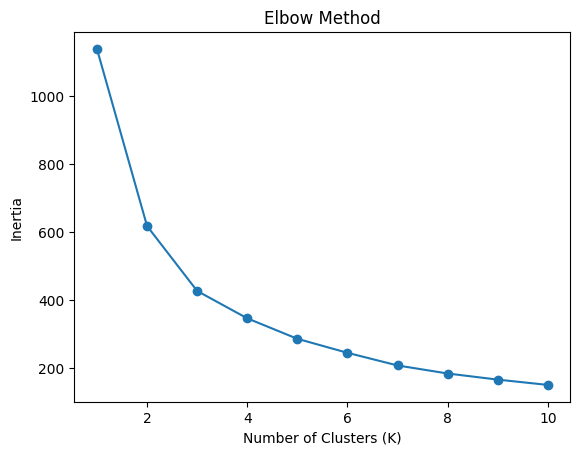


Cluster labels:
[1 0 0 1 0 1 0 1 1 0 0 1 0 0 0 0 1 0 0 1 1 1 1 0 0 1 0 0 0 1 0 1 0 0 1 0 0
 1 0 1 1 1 0 1 1 0 1 1 1 0 1 1 1 0 0 1 0 0 1 1 1 1 0 1 0 0 1 1 1 1 0 1 0 1
 1 0 1 0 0 1 1 1 0 0 1 0 0 0 1 1 0 0 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1
 1 1 1 1 1 1 1 0 0 1 0 0 1 1 1 0 0 1 0 1 0 0 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 0 0 1 1 1 0 0 1 0 1 1 0 0 1 1 1 1 1 1 1 1 0 1 1 0 0 0 1 0
 1 0 1 1 1 0 1 1 0 0 1 0 0 0 1 1 0 0 0 1 1 1 0 0 1 0 1 0 0 0 1 1 1 0 0 1 1
 1 0 1 1 1 1 0 1 0 0 0 0 1 0 0 0 0 0 1 1 1 0 0 1 1 1 1 1 0 1 0 0 0 1 0 1 0
 0 0 0 0 0 0 0 1 0 1 1 1 1 0 1 0 1 1 0 1 1 0 1 0 0 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 0 1 0 1 1 0 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 1 0 1 1 1 1 0 0 1 1 1
 1 1 0 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 0 0 0 1 1 1 1 1 1 1 1 1 0 1 0 0 1 0 0
 0 1 0 0 1 1 1 0 1 1 1 1 1 1 1 0 1 1 1 0 1 1 0 0 1 1 1 1 1 1 0 1 1 1 1 1 1
 1 0 1 1 1 1 0 0 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1 0 0 1 1 1 1 1 1 1 0 1 1
 0 0 0 1 1 0 1 0 0 1 1 0 0 0 0 0 0 0 0 1 1 1 1 1 0 1 1 0 1 0 1 1 1 1 1 0 1
 1 1 1 1

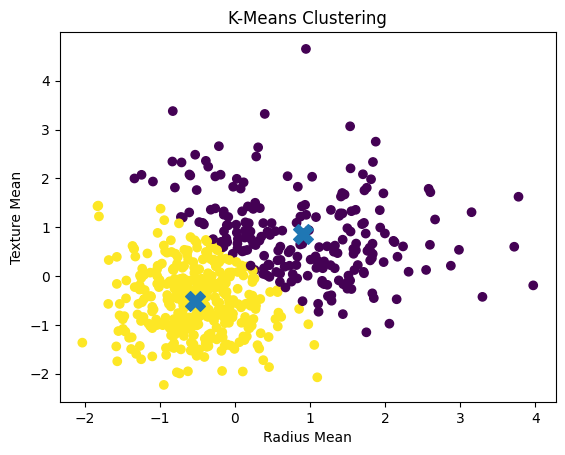

In [4]:
# part 1 of question 6 - K-MEANS CLUSTERING

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data.csv")

print("Dataset before removing unnecessary columns:")
print(df.head())

# Remove unnecessary columns
if 'id' in df.columns:
    df.drop(columns=['id'], inplace=True)

if 'Unnamed: 32' in df.columns:
    df.drop(columns=['Unnamed: 32'], inplace=True)

print("\nDataset after removing unnecessary columns:")
print(df.head())

# We use two numerical features for clustering

X = df[['radius_mean', 'texture_mean']]

print("\nSelected features:")
print(X.head())

print("\nMissing values:")
print(X.isnull().sum())

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


# FIND APPROPRIATE K USING ELBOW METHOD
#The Elbow Method is a simple method used to find the best number of groups (called K or clusters) when using the K-Means clustering algorithm

inertia = []
for k in range(1, 11):
    model = KMeans(n_clusters=k,random_state=42,n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)
print("\nInertia values:")
for k, value in zip(range(1, 11), inertia):
    print("K =", k, "Inertia =", value)

# Plot elbow curve
plt.plot(
    range(1, 11),
    inertia,
    marker='o'
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()


#APPLY K-MEANS
# choose K = 2

k = 2

kmeans = KMeans(n_clusters=k,random_state=42,n_init=10)
kmeans.fit(X_scaled)

# GET CLUSTER LABELS

labels = kmeans.labels_

print("\nCluster labels:")
print(labels)

# GET CENTROIDS

centroids = kmeans.cluster_centers_

print("\nCluster centroids:")
print(centroids)


# ADD CLUSTER LABELS TO DATAFRAME

df['Cluster'] = labels

print("\nData with cluster labels:")
print(df[['radius_mean', 'texture_mean', 'Cluster']].head(20))


# PLOT K-MEANS CLUSTERS

plt.scatter(X_scaled[:, 0],X_scaled[:, 1],c=labels)
plt.scatter(centroids[:, 0],centroids[:, 1],marker='X',s=200)
plt.xlabel("Radius Mean")
plt.ylabel("Texture Mean")
plt.title("K-Means Clustering")
plt.show()

Dataset before removing unnecessary columns:
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_w

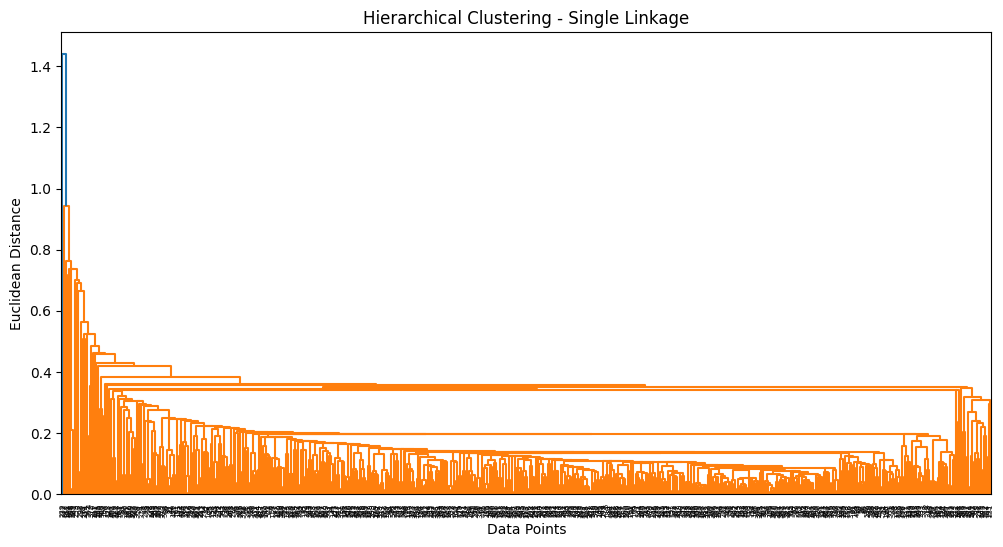

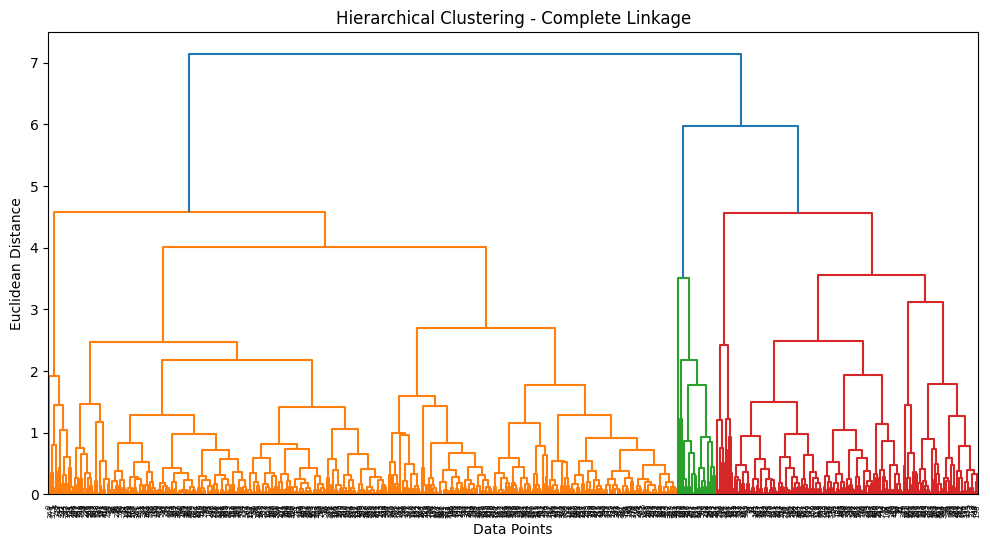

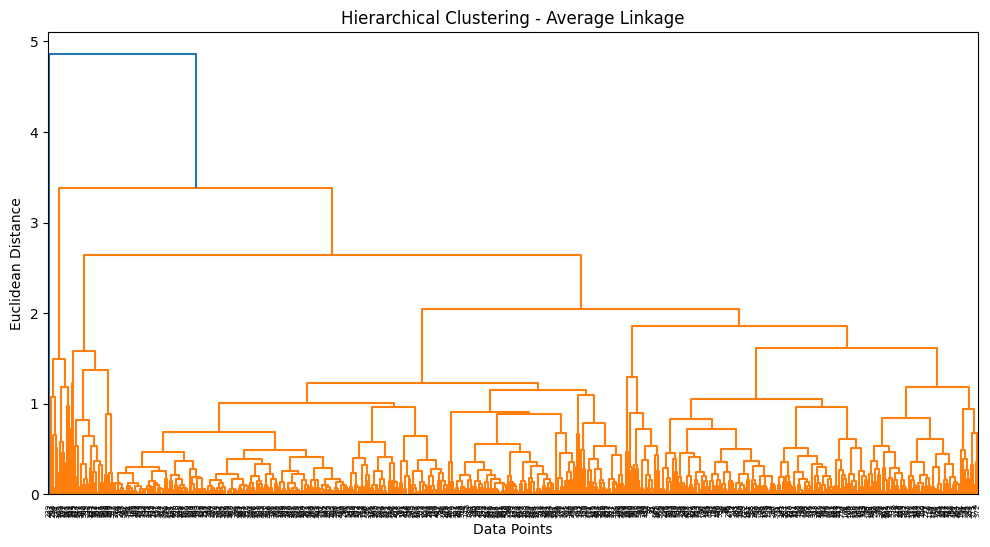


Hierarchical Clustering Results:
    Radius Mean  Texture Mean  Single Linkage  Complete Linkage  \
0         17.99         10.38               1                 1   
1         20.57         17.77               1                 1   
2         19.69         21.25               1                 2   
3         11.42         20.38               1                 1   
4         20.29         14.34               1                 1   
5         12.45         15.70               1                 1   
6         18.25         19.98               1                 2   
7         13.71         20.83               1                 1   
8         13.00         21.82               1                 1   
9         12.46         24.04               1                 1   
10        16.02         23.24               1                 2   
11        15.78         17.89               1                 2   
12        19.17         24.80               1                 2   
13        15.85         23.9

In [5]:
# HIERARCHICAL CLUSTERING

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import (linkage,dendrogram,fcluster)

df = pd.read_csv("data.csv")

print("Dataset before removing unnecessary columns:")
print(df.head())

# Remove unnecessary columns

if 'id' in df.columns:
    df.drop(columns=['id'], inplace=True)

if 'Unnamed: 32' in df.columns:
    df.drop(columns=['Unnamed: 32'], inplace=True)

print("\nDataset after removing unnecessary columns:")
print(df.head())

X = df[['radius_mean', 'texture_mean']]

print("\nSelected features:")
print(X.head())

print("\nMissing values:")
print(X.isnull().sum())

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


# SINGLE LINKAGE

single_linkage = linkage(
    X_scaled,
    method='single',
    metric='euclidean'
)

#COMPLETE LINKAGE

complete_linkage = linkage(
    X_scaled,
    method='complete',
    metric='euclidean'
)


#AVERAGE LINKAGE

average_linkage = linkage(
    X_scaled,
    method='average',
    metric='euclidean'
)


# SINGLE LINKAGE DENDROGRAM

plt.figure(figsize=(12, 6))

dendrogram(
    single_linkage
)

plt.title("Hierarchical Clustering - Single Linkage")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")

plt.show()


# COMPLETE LINKAGE DENDROGRAM

plt.figure(figsize=(12, 6))

dendrogram(
    complete_linkage
)

plt.title("Hierarchical Clustering - Complete Linkage")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")

plt.show()


# AVERAGE LINKAGE DENDROGRAM

plt.figure(figsize=(12, 6))

dendrogram(
    average_linkage
)

plt.title("Hierarchical Clustering - Average Linkage")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")

plt.show()


# CREATE 2 CLUSTERS

single_clusters = fcluster(
    single_linkage,
    t=2,
    criterion='maxclust'
)

complete_clusters = fcluster(
    complete_linkage,
    t=2,
    criterion='maxclust'
)

average_clusters = fcluster(
    average_linkage,
    t=2,
    criterion='maxclust'
)


# DISPLAY CLUSTER ASSIGNMENTS

result = pd.DataFrame({

    'Radius Mean': df['radius_mean'],

    'Texture Mean': df['texture_mean'],

    'Single Linkage': single_clusters,

    'Complete Linkage': complete_clusters,

    'Average Linkage': average_clusters

})


print("\nHierarchical Clustering Results:")
print(result.head(20))


# NUMBER OF POINTS IN EACH CLUSTER

print("\nSingle Linkage cluster counts:")
print(pd.Series(single_clusters).value_counts())

print("\nComplete Linkage cluster counts:")
print(pd.Series(complete_clusters).value_counts())

print("\nAverage Linkage cluster counts:")
print(pd.Series(average_clusters).value_counts())

In [6]:
# ENSEMBLE METHODS
# RANDOM FOREST AND ADABOOST

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import (RandomForestClassifier,AdaBoostClassifier)
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix)

df = pd.read_csv("data.csv")

print("Dataset before removing unnecessary columns:\n")
print(df.head())

# Remove ID column
if 'id' in df.columns:
    df.drop(columns=['id'], inplace=True)

# Remove unnecessary empty column
if 'Unnamed: 32' in df.columns:
    df.drop(columns=['Unnamed: 32'], inplace=True)


print("\nDataset after removing unnecessary columns:\n")
print(df.head())

print("\nCategorical columns:")
print(df.select_dtypes(include='object').columns.tolist())

print("\nNumerical columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

print("\nMissing values:")

missing = df.isnull().sum()

missing_percent = (missing / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": missing_percent
})

print(missing_table)


#CONVERT TARGET VARIABLE

# M = Malignant = 1
# B = Benign    = 0

df['diagnosis'] = df['diagnosis'].map({
    'M': 1,
    'B': 0
})

X = df.drop('diagnosis', axis=1)

y = df['diagnosis']


print("\nNumber of samples:", X.shape[0])
print("Number of features:", X.shape[1])

print("\nClass distribution:")
print(y.value_counts())

print("\nClass distribution in percentage:")
print(y.value_counts(normalize=True))

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.30,random_state=42,stratify=y)


#RANDOM FOREST - BAGGING

random_forest = RandomForestClassifier(n_estimators=100,random_state=42)

# Train Random Forest

random_forest.fit(X_train,y_train)

# Make predictions

rf_pred = random_forest.predict(X_test)


# RANDOM FOREST EVALUATION

print("RANDOM FOREST CLASSIFIER - BAGGING")

print(
    "Accuracy:",
    accuracy_score(y_test, rf_pred)
)

print(
    "Precision:",
    precision_score(
        y_test,
        rf_pred,
        average='weighted'
    )
)

print(
    "Recall:",
    recall_score(
        y_test,
        rf_pred,
        average='weighted'
    )
)

print(
    "F1 Score:",
    f1_score(
        y_test,
        rf_pred,
        average='weighted'
    )
)


print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        rf_pred
    )
)


# FEATURE IMPORTANCE - RANDOM FOREST

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': random_forest.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("\nRandom Forest Feature Importance:")
print(feature_importance)


#ADABOOST - BOOSTING

adaboost = AdaBoostClassifier(n_estimators=100,learning_rate=1.0,random_state=42)

# Train AdaBoost

adaboost.fit(
    X_train,
    y_train
)

# Make predictions

ada_pred = adaboost.predict(
    X_test
)


# ADABOOST EVALUATION

print("ADABOOST CLASSIFIER - BOOSTING")

print(
    "Accuracy:",
    accuracy_score(y_test, ada_pred)
)

print(
    "Precision:",
    precision_score(
        y_test,
        ada_pred,
        average='weighted'
    )
)

print(
    "Recall:",
    recall_score(
        y_test,
        ada_pred,
        average='weighted'
    )
)

print(
    "F1 Score:",
    f1_score(
        y_test,
        ada_pred,
        average='weighted'
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        ada_pred
    )
)

# FEATURE IMPORTANCE - ADABOOST

ada_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': adaboost.feature_importances_

})

ada_importance = ada_importance.sort_values(
    by='Importance',
    ascending=False
)


print("\nAdaBoost Feature Importance:")
print(ada_importance)


# COMPARE RANDOM FOREST AND ADABOOST

comparison = pd.DataFrame({

    'Model': [
        'Random Forest',
        'AdaBoost'
    ],

    'Accuracy': [
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, ada_pred)
    ],

    'Precision': [
        precision_score(
            y_test,
            rf_pred,
            average='weighted'
        ),
        precision_score(
            y_test,
            ada_pred,
            average='weighted'
        )
    ],

    'Recall': [
        recall_score(
            y_test,
            rf_pred,
            average='weighted'
        ),
        recall_score(
            y_test,
            ada_pred,
            average='weighted'
        )
    ],

    'F1 Score': [
        f1_score(
            y_test,
            rf_pred,
            average='weighted'
        ),
        f1_score(
            y_test,
            ada_pred,
            average='weighted'
        )
    ]

})


print("ENSEMBLE MODEL COMPARISON")
print(comparison.to_string(index=False))

Dataset before removing unnecessary columns:

         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_

Dataset before removing unnecessary columns:

         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_

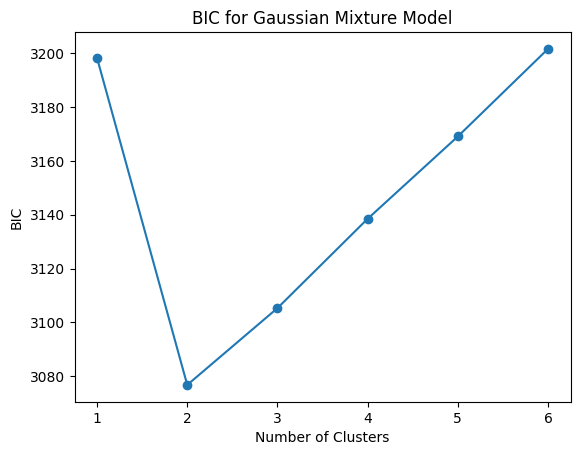

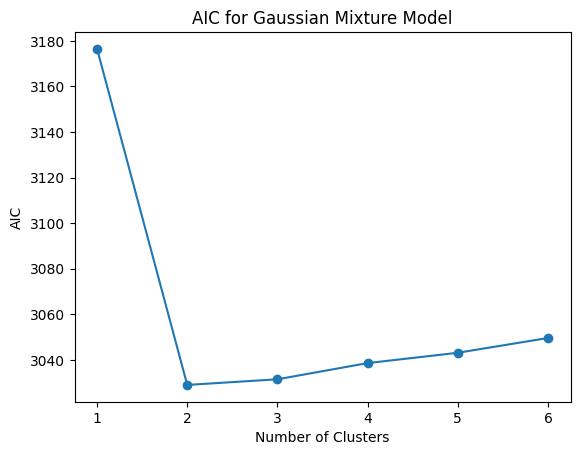


Best number of clusters according to BIC: 2

Cluster labels:
[0 0 0 1 0 1 0 1 1 0 0 1 0 0 0 0 1 0 0 1 1 1 1 0 0 0 1 0 0 0 0 1 0 0 1 0 1
 1 0 1 1 1 0 1 1 0 1 1 1 1 1 1 1 0 0 1 0 0 1 1 1 1 0 1 0 0 1 1 1 1 0 1 0 1
 1 0 1 0 0 1 1 1 0 0 1 0 1 0 1 1 0 0 1 1 1 0 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1
 1 1 1 1 1 1 1 0 0 1 0 0 1 1 1 0 0 1 0 1 1 0 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 0 0 1 1 1 0 0 1 0 1 1 0 0 1 1 1 1 1 1 1 1 0 1 1 0 0 0 1 0
 1 0 1 1 1 0 1 1 0 0 1 1 0 0 1 1 0 0 0 1 1 1 0 1 1 0 1 0 0 0 1 1 1 0 0 1 1
 1 0 1 1 1 1 0 1 0 0 0 0 1 1 0 0 0 0 1 1 1 0 0 1 1 1 0 1 0 1 0 0 0 1 0 1 0
 0 0 0 0 1 0 0 1 1 1 1 1 1 0 1 0 1 1 0 1 1 0 1 0 0 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 0 1 0 1 1 0 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 1 0 1 1 1 1 0 0 1 1 1
 1 1 0 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 1 1 1 0 1 0 0 1 0 0
 0 1 0 0 1 1 1 0 1 1 1 1 1 1 1 0 1 1 1 0 1 1 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1
 1 0 1 1 1 1 0 0 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1 0 0 1 1 1 1 1 1 1 0 1 1
 0 0 0 1 1 0 1 0 0 1 1 0 0 0 0 0 0 0 0

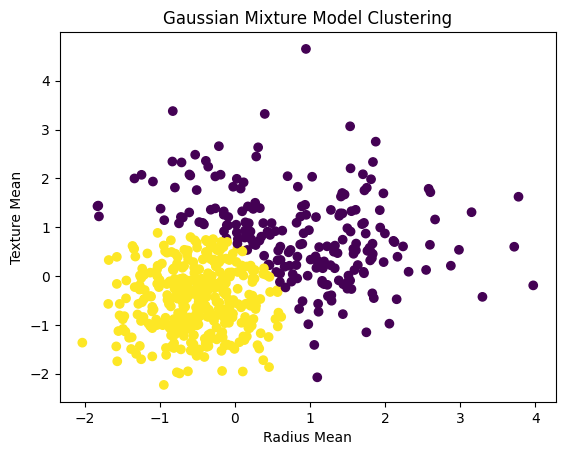

In [2]:
#GAUSSIAN MIXTURE MODEL (GMM) FOR CLUSTERING

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture

df = pd.read_csv("data.csv")

print("Dataset before removing unnecessary columns:\n")
print(df.head())

if 'id' in df.columns:
    df.drop(columns=['id'], inplace=True)

if 'Unnamed: 32' in df.columns:
    df.drop(columns=['Unnamed: 32'], inplace=True)


print("\nDataset after removing unnecessary columns:\n")
print(df.head())

print("\nCategorical columns:")
print(df.select_dtypes(include='object').columns.tolist())

print("\nNumerical columns:")
print(df.select_dtypes(include=np.number).columns.tolist())


print("\nMissing values:")

missing = df.isnull().sum()

missing_percent = (missing / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": missing_percent
})

print(missing_table)

# Diagnosis is not used because GMM is unsupervised.
# We use two numerical features so that we can visualize
# the clusters easily.

X = df[['radius_mean', 'texture_mean']]

print("\nSelected features:")
print(X.head())

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

bic_values = []
aic_values = []

cluster_range = range(1, 7)

for k in cluster_range:

    gmm = GaussianMixture(n_components=k,random_state=42)
    gmm.fit(X_scaled)

    bic_values.append(gmm.bic(X_scaled))
    aic_values.append(gmm.aic(X_scaled))

print("\nBIC values:")

for k, value in zip(cluster_range, bic_values):
    print("Number of clusters =", k, "BIC =", value)

print("\nAIC values:")

for k, value in zip(cluster_range, aic_values):
    print("Number of clusters =", k, "AIC =", value)

# PLOT BIC

plt.plot(cluster_range,bic_values,marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("BIC")
plt.title("BIC for Gaussian Mixture Model")
plt.show()

# PLOT AIC

plt.plot(cluster_range,aic_values,marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("AIC")
plt.title("AIC for Gaussian Mixture Model")
plt.show()


#SELECT NUMBER OF CLUSTERS
# Select the number of components having the lowest BIC

best_k = cluster_range[
    np.argmin(bic_values)
]

print("\nBest number of clusters according to BIC:",
      best_k)


# CREATE FINAL GMM MODEL

gmm = GaussianMixture(
    n_components=best_k,
    random_state=42
)

# Train the model

gmm.fit(X_scaled)


# PREDICT CLUSTER LABELS

labels = gmm.predict(X_scaled)

print("\nCluster labels:")
print(labels)


#CLUSTER PROBABILITIES

probabilities = gmm.predict_proba(X_scaled)
print("\nCluster probabilities for first 10 data points:")
print(probabilities[:10])


#ADD CLUSTER LABELS TO DATAFRAME

df['Cluster'] = labels
print("\nData with cluster labels:")
print(df[['radius_mean', 'texture_mean', 'Cluster']].head(20))

# DISPLAY CLUSTER COUNTS

print("\nNumber of data points in each cluster:")

print(df['Cluster'].value_counts())


#DISPLAY GMM PARAMETERS

print("\nGMM Means:")
print(gmm.means_)

print("\nGMM Covariance Matrices:")
print(gmm.covariances_)

print("\nGMM Weights:")
print(gmm.weights_)


# VISUALIZE GMM CLUSTERS
plt.scatter(X_scaled[:, 0],X_scaled[:, 1],c=labels)
plt.xlabel("Radius Mean")
plt.ylabel("Texture Mean")
plt.title("Gaussian Mixture Model Clustering")
plt.show()

Dataset before removing unnecessary columns:

         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_

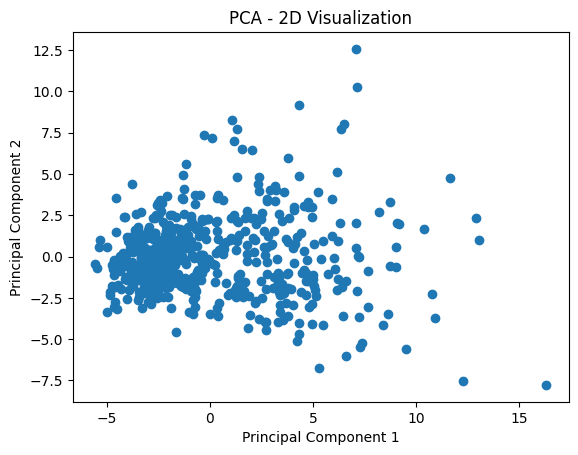

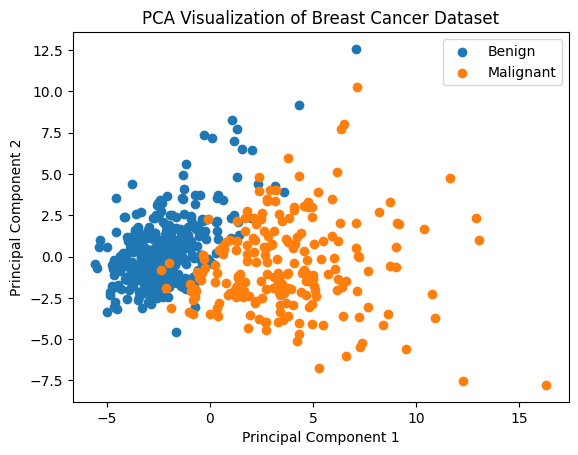

In [3]:
#PRINCIPAL COMPONENT ANALYSIS (PCA)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv("data.csv")

print("Dataset before removing unnecessary columns:\n")
print(df.head())

if 'id' in df.columns:
    df.drop(columns=['id'], inplace=True)

if 'Unnamed: 32' in df.columns:
    df.drop(columns=['Unnamed: 32'], inplace=True)

print("\nDataset after removing unnecessary columns:\n")
print(df.head())

print("\nCategorical columns:")
print(df.select_dtypes(include='object').columns.tolist())

print("\nNumerical columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

print("\nMissing values:")

missing = df.isnull().sum()

missing_percent = (missing / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": missing_percent
})

print(missing_table)

df['diagnosis'] = df['diagnosis'].map({
    'M': 1,
    'B': 0
})


X = df.drop('diagnosis', axis=1)
y = df['diagnosis']
print("\nNumber of features before PCA:")
print(X.shape[1])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# APPLY PCA
# Reduce all features to 2 principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)


#DISPLAY PCA RESULTS
print("\nShape before PCA:")
print(X_scaled.shape)

print("\nShape after PCA:")
print(X_pca.shape)

print("\nPrincipal Components:")
print(X_pca[:10])


#EXPLAINED VARIANCE

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal explained variance:")
print(pca.explained_variance_ratio_.sum())


#PCA COMPONENTS

components = pd.DataFrame(pca.components_,columns=X.columns,index=['PC1','PC2'])
print("\nPCA Components:")
print(components)


#VISUALIZE PCA RESULTS

plt.scatter(X_pca[:, 0],X_pca[:, 1])
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - 2D Visualization")
plt.show()


# VISUALIZE PCA USING DIAGNOSIS
# Diagnosis is used ONLY for visualization.
# It is NOT used to calculate PCA.

plt.scatter(X_pca[y == 0, 0],X_pca[y == 0, 1],label='Benign')
plt.scatter(X_pca[y == 1, 0],X_pca[y == 1, 1],label='Malignant')
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Breast Cancer Dataset")
plt.legend()

plt.show()

3 - Analyse the performance of the different models developed in question (1) and (2) using appropriate metrices.

The performance of the implemented models was evaluated using suitable metrics based on the type of machine learning problem.

For regression, MSE, RMSE, MAE and R² were used. Linear Regression achieved an MSE of 0.099954, RMSE of 0.316155, MAE of 0.260690 and R² of 0.752595. Ridge Regression gave almost the same performance, while Lasso Regression had a slightly higher error and lower R² of 0.734087. Hence, Linear Regression performed slightly better for this dataset.

For classification, accuracy, precision, recall, F1-score and confusion matrix were used. Decision Tree with Gini impurity achieved 90.06% accuracy, whereas Entropy achieved 94.15%, showing that Entropy was better for this dataset. Normal Logistic Regression achieved 94.74% accuracy, Ridge Logistic Regression achieved 97.08%, and Lasso Logistic Regression achieved the highest accuracy of 98.83%. Therefore, Lasso Logistic Regression was the best among the classification models.

KNN achieved 96.49% accuracy for K = 5, while Naive Bayes achieved 93.57% accuracy. Random Forest achieved 96.49% accuracy and AdaBoost achieved 97.66% accuracy. Thus, AdaBoost performed better than Random Forest.

For clustering, K-Means was evaluated using inertia, which decreased as the number of clusters increased. Hierarchical Clustering was compared using single, complete and average linkage. Complete linkage produced a more balanced clustering than single and average linkage. For GMM, BIC and AIC were used, and both gave their lowest values for 2 components. Therefore, 2 clusters were selected for GMM.

For PCA, explained variance was used. The original 30 features were reduced to 2 principal components. PC1 explained 44.27% and PC2 explained 18.97% of the variance, giving a total explained variance of 63.24%.

Therefore, Linear Regression performed best among the regression models, while Lasso Logistic Regression performed best among the classification models. AdaBoost was the better-performing ensemble method, and GMM selected 2 components based on BIC and AIC.

